# 06 · Model Karşılaştırma Sonuçları

**Amaç:** `03_train_baseline` ve `05_train_comparison` defterlerinin Drive'a kaydettiği `results.json` ve `history.json` dosyalarını okuyup tek tabloda ve grafiklerde karşılaştırmak.

* Bu defter **eğitim yapmaz**. 1–3. bölümler yalnızca kayıtları okur; veri ya da GPU gerektirmez.
* **4. bölüm (test değerlendirmesi, Faz 3)** doğrulama ve test kümelerini belleğe alır ve her modelin skorlarını hesaplar. GPU önerilir (T4'te birkaç dakika); skorlar model klasörüne `preds.parquet` olarak kaydedilir, sonraki çalıştırmalarda yeniden hesaplanmaz.
* 2. kod hücresindeki `HIZLI_MOD` ayarıyla:
  * `HIZLI_MOD = False` *(nihai rapor)*: sadece tam eğitimleri (`2015, 2017, 2019`) okur, `_hizli` klasörlerini dışarıda bırakır.
  * `HIZLI_MOD = True` *(ön izleme)*: sadece `_hizli` denemelerini (`2017`) okuyup kendi aralarında karşılaştırır.
* Üretilen tablo ve şekiller `results/` klasörüne kaydedilir.

In [14]:
# --- Kurulum: hem Google Colab'da hem kendi bilgisayarında çalışır ---
import json, os, sys
from pathlib import Path

BOOTSTRAP_BRANCH = os.environ.get("TORNADO_BRANCH", "main")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")                     # işlenmiş veri ve modeller Drive'da saklanır
    REPO = Path("/content/tornado-cnn")
    cfg_file = REPO / "configs" / "experiments.json"
    branch = json.loads(cfg_file.read_text())["repo"]["branch"] if cfg_file.exists() else BOOTSTRAP_BRANCH
    if not REPO.exists():
        try:                                          # repo private ise: Colab Secrets'taki token
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:                             # repo public ise token gerekmez
            token = ""
        !git clone -q -b {branch} https://{token}github.com/baevv/tornado-cnn.git {REPO}
    else:
        !git -C {REPO} fetch -q origin {branch}
        !git -C {REPO} checkout -q {branch}
        !git -C {REPO} pull -q origin {branch}
    os.chdir(REPO)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    cfg_file = REPO / "configs" / "experiments.json"
    branch = json.loads(cfg_file.read_text())["repo"]["branch"] if cfg_file.exists() else BOOTSTRAP_BRANCH

sys.path.insert(0, str(REPO))
for _m in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]

print("Colab" if IN_COLAB else "Yerel", "| repo:", REPO, "| dal:", branch)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab | repo: /content/tornado-cnn | dal: main


In [15]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.helper import paths

HIZLI_MOD = False  # True: _hizli (2017) denemelerini göster | False: sadece tam eğitimler (nihai)

try:
    data_root, primary_models = paths.prepare_colab_dirs()
    SEARCH_ROOTS = list(dict.fromkeys([primary_models, data_root.parent / "models"]))
except FileNotFoundError:
    SEARCH_ROOTS = [paths.models_root()]

RESULTS_DIR = REPO / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SUFFIX = "_hizli" if HIZLI_MOD else ""

exp_registry = paths.load_config("experiments.json")
EXPERIMENTS = {}
for item in (exp_registry.get("baselines", []) + exp_registry.get("experiments", [])):
    key = f"{item['name']}_hizli" if HIZLI_MOD else item["name"]
    lbl = f"{item['label']} [hızlı]" if HIZLI_MOD else item["label"]
    EXPERIMENTS[key] = lbl

import re


def seed_group(folder: str):
    """"03_baseline_s7_hizli" → ("03_baseline_hizli", 7); seed eki yoksa (klasör, None). Karar M3."""
    m = re.match(r"^(.*)_s(\d+)(_hizli)?$", folder)
    return (m.group(1) + (m.group(3) or ""), int(m.group(2))) if m else (folder, None)


def seed_label(folder: str) -> str:
    """Ek seed klasörüne okunur ad: deneyin etiketi + " · seed 7"."""
    base, seed = seed_group(folder)
    return f"{EXPERIMENTS.get(base, base)} · seed {seed}" if seed is not None else folder


# Eşleşen ek klasörleri otomatik ekle (HIZLI_MOD=False iken _hizli asla alınmaz)
for root in SEARCH_ROOTS:
    if root.exists():
        for d in sorted(root.iterdir()):
            if not d.is_dir():
                continue
            if HIZLI_MOD:
                if d.name.endswith("_hizli") and d.name not in EXPERIMENTS:
                    EXPERIMENTS[d.name] = seed_label(d.name)
            else:
                if d.name.startswith(("03_", "05_")) and "_hizli" not in d.name and d.name not in EXPERIMENTS:
                    EXPERIMENTS[d.name] = seed_label(d.name)

def find_model_dir(folder: str):
    for root in SEARCH_ROOTS:
        if (root / folder / "results.json").exists():
            return root / folder
    return None

found, missing = [], []
for folder, label in EXPERIMENTS.items():
    if not HIZLI_MOD and "_hizli" in folder:
        continue
    if HIZLI_MOD and not folder.endswith("_hizli"):
        continue
    mdir = find_model_dir(folder)
    if mdir is not None:
        found.append((folder, label, mdir))
    else:
        missing.append(folder)

print("Mod:", "HIZLI (_hizli, 2017)" if HIZLI_MOD else "TAM EĞİTİM")
print("Aranan model klasörleri:", SEARCH_ROOTS)
print("Bulunanlar:", [f for f, _, _ in found])
if missing:
    print("Henüz eğitilmemiş (atlandı):", missing)

Mod: TAM EĞİTİM
Aranan model klasörleri: [PosixPath('/content/drive/MyDrive/tornado-cnn/models')]
Bulunanlar: ['03_baseline', '03_mit', '05_cnn_avg', '05_resnet18_pretrained', '05_resnet18_scratch', '05_cnn_bn', '05_cnn_coord', '05_cnn_aug', '05_cnn_ls', '03_baseline_s123', '03_baseline_s7', '05_resnet18_pretrained_s123', '05_resnet18_pretrained_s7']


## 1. Karşılaştırma tablosu

* Dengesiz hortum verisinde doğruluk (`doğruluk`) tek başına yanıltıcı olduğundan tablo ana ölçüt olan **`PR-AUC`** değerine göre azalan sırada listelenir.
* `PR-AUC` ve `ROC-AUC` eşikten bağımsızdır. `F1`, `Recall` ve `Precision` ise doğrulama kümesinde seçilen eşikle hesaplandığından hafifçe iyimser olabilir; nihai tarafsız değerlendirmede bu eşik test kümesinde sabit tutulacaktır.

In [16]:
# Eski 03_* kayıtlarında `params` alanı yoksa TornadoCNN parametre sayısını doğrudan hesapla
def fallback_params(folder: str):
    if folder.startswith("03_"):
        try:
            from src.helper.model import TornadoCNN, count_params
            return count_params(TornadoCNN())
        except ImportError:
            return 105761
    return None

rows = []
histories = {}
best_eps = {}   # results.json'daki en iyi tur (her model kendi izlediği ölçüte göre seçti)
for folder, default_label, mdir in found:
    with open(mdir / "results.json", encoding="utf-8") as f:
        res = json.load(f)
    h_path = mdir / "history.json"
    hist = pd.read_json(h_path) if h_path.exists() else pd.DataFrame()
    if not hist.empty:
        histories[folder] = (default_label, hist)

    cfg_i = res.get("config", {})
    val = res.get("validation", {})
    best_ep = res.get("best_epoch")
    best_eps[folder] = best_ep
    val_loss = res.get("val_loss")
    if val_loss is None and not hist.empty and best_ep is not None:
        hit = hist.loc[hist["tur"] == best_ep, "doğrulama kaybı"]
        val_loss = float(hit.iloc[0]) if not hit.empty else None

    rows.append({
        "Klasör": folder,
        "Model": default_label,
        "Yıllar": ",".join(map(str, res.get("years", []))),
        "Ağırlık": cfg_i.get("weighting", "-"),
        "Parametre": res.get("params") or fallback_params(folder),
        "lr": cfg_i.get("lr"),
        "En İyi Tur": best_ep,
        "Toplam Tur": int(hist["tur"].max()) if not hist.empty else None,
        "Doğrulama Kaybı": val_loss,
        "PR-AUC": val.get("PR-AUC"),
        "ROC-AUC": val.get("ROC-AUC"),
        "F1": val.get("F1"),
        "Recall": val.get("recall (yakalama)"),
        "Precision": val.get("precision (isabet)"),
        "Doğruluk": val.get("doğruluk"),
        "Eşik": res.get("threshold"),
    })

table = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True) if rows else pd.DataFrame()
if not table.empty:
    table.to_csv(RESULTS_DIR / f"model_comparison{SUFFIX}.csv", index=False)

print("Not — Flatten kullanılsaydı: 128 × 7 × 15 = 13.440 özellik → Linear(13440, 64) = 860.224 parametre "
      "(toplam 957.729; mevcut Global Max/Avg TornadoCNN ise 105.761 parametre).")
table.round({"Doğrulama Kaybı": 4, "PR-AUC": 4, "ROC-AUC": 4, "F1": 4, "Recall": 4, "Precision": 4, "Doğruluk": 4, "Eşik": 3}) if not table.empty else table

Not — Flatten kullanılsaydı: 128 × 7 × 15 = 13.440 özellik → Linear(13440, 64) = 860.224 parametre (toplam 957.729; mevcut Global Max/Avg TornadoCNN ise 105.761 parametre).


,Klasör,Model,Yıllar,Ağırlık,Parametre,lr,En İyi Tur,Toplam Tur,Doğrulama Kaybı,PR-AUC,ROC-AUC,F1,Recall,Precision,Doğruluk,Eşik
0,05_cnn_coord,TornadoCNN (Global Max + CoordConv),"2015,2017,2019",pos_weight,106049,0.0010,7,11,0.8144,0.6022,0.8976,0.5812,0.5884,0.5743,0.9272,0.908
1,03_baseline_s123,"TornadoCNN (Global Max, pos_weight) · seed 123","2015,2017,2019",pos_weight,105761,0.0010,4,8,0.7897,0.5955,0.8942,0.5650,0.5420,0.5899,0.9284,0.844
2,05_cnn_bn,TornadoCNN (Global Max + BN),"2015,2017,2019",pos_weight,106241,0.0010,9,13,0.8581,0.5939,0.8898,0.5612,0.5681,0.5545,0.9238,0.822
3,03_mit,"TornadoCNN (Global Max, mit)","2015,2017,2019",mit,105761,0.0010,7,11,0.1910,0.5883,0.8803,0.5788,0.5826,0.5751,0.9272,0.348
4,05_cnn_ls,TornadoCNN (Global Max + label smoothing),"2015,2017,2019",pos_weight,105761,0.0010,7,11,0.8733,0.5879,0.8847,0.5662,0.5174,0.6252,0.9320,0.790
5,05_cnn_avg,TornadoCNN (Global Avg),"2015,2017,2019",pos_weight,105761,0.0010,10,14,0.8533,0.5858,0.8816,0.5716,0.5696,0.5737,0.9267,0.795
6,03_baseline,"TornadoCNN (Global Max, pos_weight)","2015,2017,2019",pos_weight,105761,0.0010,5,9,0.8546,0.5843,0.8823,0.5702,0.5739,0.5665,0.9257,0.731
7,05_cnn_aug,TornadoCNN (Global Max + augmentation),"2015,2017,2019",pos_weight,105761,0.0010,6,10,0.8511,0.5776,0.8813,0.5613,0.5174,0.6134,0.9306,0.887
8,03_baseline_s7,"TornadoCNN (Global Max, pos_weight) · seed 7","2015,2017,2019",pos_weight,105761,0.0010,4,8,0.8463,0.5671,0.8798,0.5641,0.6246,0.5143,0.9172,0.746
9,05_resnet18_pretrained_s123,ResNet-18 (ön-eğitimli) · seed 123,"2015,2017,2019",pos_weight,11177025,0.0001,2,6,0.9415,0.5471,0.8916,0.5747,0.5797,0.5698,0.9264,0.967


### Seed'ler arası değişkenlik (karar M3)

Ana karşılaştırmanın iki modeli (TornadoCNN temel ve ResNet-18 ön-eğitimli) 3 seed ile eğitildi (`<ad>`, `<ad>_s7`, `<ad>_s123`). Tablo, birden fazla seed'i olan her deney için ortalama ± std verir.

**Nasıl okunur:** Temel modelin PR-AUC std'si **gürültü ölçüsüdür**. Tek seed ile eğitilen bir ablasyonun temel modele farkı bu std'den küçükse, fark yorumlanmaz.

In [17]:
if not table.empty:
    t = table.assign(Deney=[seed_group(f)[0] for f in table["Klasör"]])
    counts = t.groupby("Deney").size()
    multi = counts[counts >= 2].index
    if len(multi):
        cols = ["PR-AUC", "ROC-AUC", "F1", "Eşik", "En İyi Tur"]
        g = t[t["Deney"].isin(multi)].groupby("Deney")[cols]
        seed_table = g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)
        seed_table.insert(0, "seed sayısı", counts[multi])
        seed_table.to_csv(RESULTS_DIR / f"seed_summary{SUFFIX}.csv")
        display(seed_table)
        base = next((d for d in multi if d.startswith("03_baseline")), None)
        if base is not None:
            noise = float(t.loc[t["Deney"] == base, "PR-AUC"].std())
            print(f"Gürültü ölçüsü (temel modelin PR-AUC std'si): {noise:.4f}. "
                  "Ablasyonların temel modele farkı bundan küçükse yorumlanmaz.")
    else:
        print("Henüz birden fazla seed ile eğitilmiş deney yok (05 defteri, 8. bölüm).")

,seed sayısı,PR-AUC,ROC-AUC,F1,Eşik,En İyi Tur
Deney,,,,,,
03_baseline,3,0.5823 ± 0.0143,0.8854 ± 0.0077,0.5664 ± 0.0033,0.7734 ± 0.0612,4.3333 ± 0.5774
05_resnet18_pretrained,3,0.5334 ± 0.0165,0.8807 ± 0.0104,0.5513 ± 0.0224,0.9382 ± 0.0647,2.3333 ± 0.5774


Gürültü ölçüsü (temel modelin PR-AUC std'si): 0.0143. Ablasyonların temel modele farkı bundan küçükse yorumlanmaz.


## 2. Öğrenme eğrileri

Üstteki grafiklerde her modelin **eğitim ve doğrulama kaybı** kendi ölçeğinde (farklı `pos_weight` değerleri kayıp ölçeğini değiştirdiği için ayrı eksenlerde), alttaki iki grafikte ise modellerin **doğrulama PR-AUC ve ROC-AUC** gidişatı ortak eksende gösterilir.

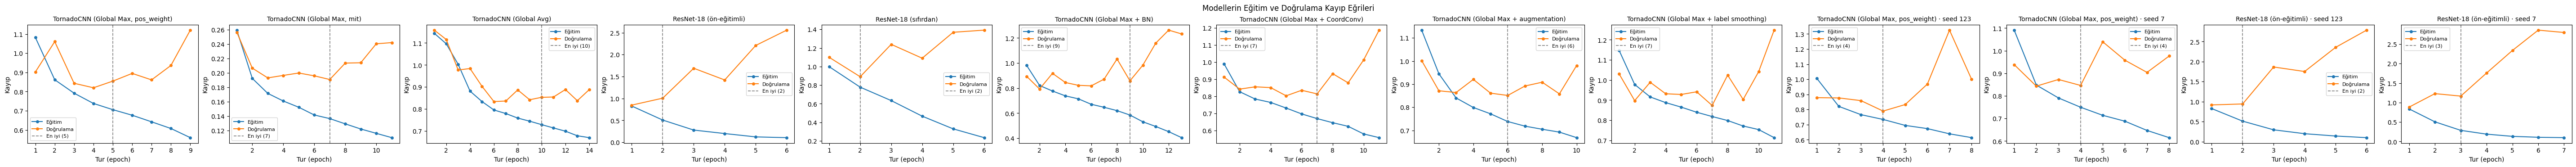

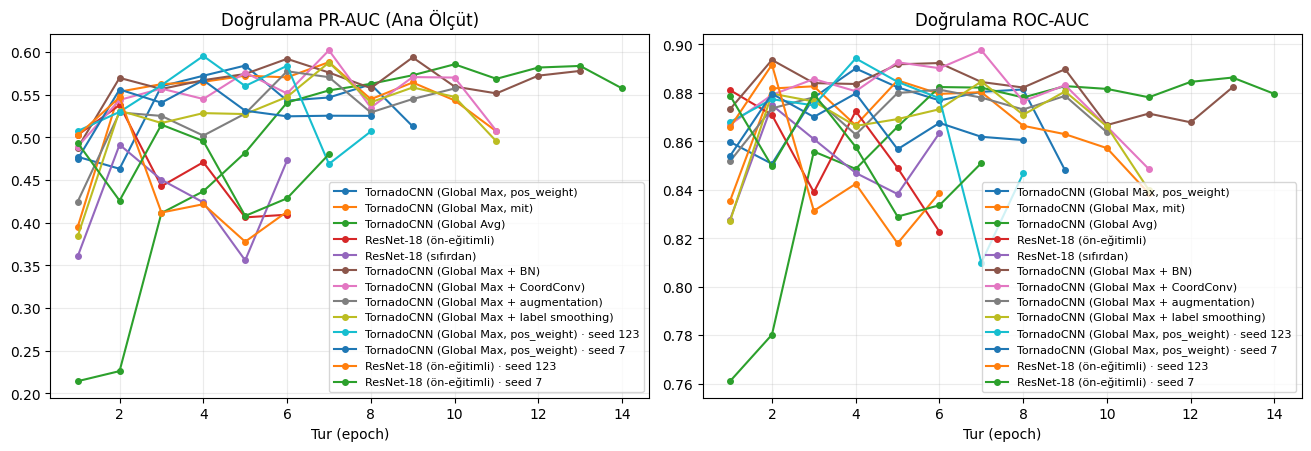

In [18]:
if histories:
    n = len(histories)
    ncol = min(4, n)
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.4 * nrow), layout="constrained", squeeze=False)
    axes = axes.ravel()
    for ax, (folder, (label, hist)) in zip(axes, histories.items()):
        best_ep = best_eps.get(folder) or int(hist.loc[hist["doğrulama PR-AUC"].idxmax(), "tur"])
        ax.plot(hist["tur"], hist["eğitim kaybı"], "o-", ms=4, label="Eğitim")
        ax.plot(hist["tur"], hist["doğrulama kaybı"], "o-", ms=4, label="Doğrulama")
        ax.axvline(best_ep, color="gray", ls="--", lw=1.2, label=f"En iyi ({best_ep})")
        ax.set_title(label, fontsize=10)
        ax.set_xlabel("Tur (epoch)")
        ax.set_ylabel("Kayıp")
        ax.legend(fontsize=8)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Modellerin Eğitim ve Doğrulama Kayıp Eğrileri")
    fig.savefig(RESULTS_DIR / f"learning_curves_loss{SUFFIX}.png", dpi=150)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
    # Aynı deneyin seed'leri aynı renkte, farklı çizgi stiliyle (düz, kesikli, noktalı)
    bases = list(dict.fromkeys(seed_group(f)[0] for f in histories))
    palette = plt.get_cmap("tab10" if len(bases) <= 10 else "tab20")
    styles, used = ["-", "--", ":", "-."], {}
    for folder, (label, hist) in histories.items():
        base = seed_group(folder)[0]
        i = used.get(base, 0)
        used[base] = i + 1
        kw = dict(color=palette(bases.index(base) % palette.N), ls=styles[i % len(styles)], marker="o", ms=4, label=label)
        axes[0].plot(hist["tur"], hist["doğrulama PR-AUC"], **kw)
        axes[1].plot(hist["tur"], hist["doğrulama AUC"], **kw)
    axes[0].set_title("Doğrulama PR-AUC (Ana Ölçüt)")
    axes[1].set_title("Doğrulama ROC-AUC")
    for ax in axes:
        ax.set_xlabel("Tur (epoch)")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.savefig(RESULTS_DIR / f"learning_curves_auc{SUFFIX}.png", dpi=150)
    plt.show()

## 3. Doğrulama ölçütlerinin karşılaştırması

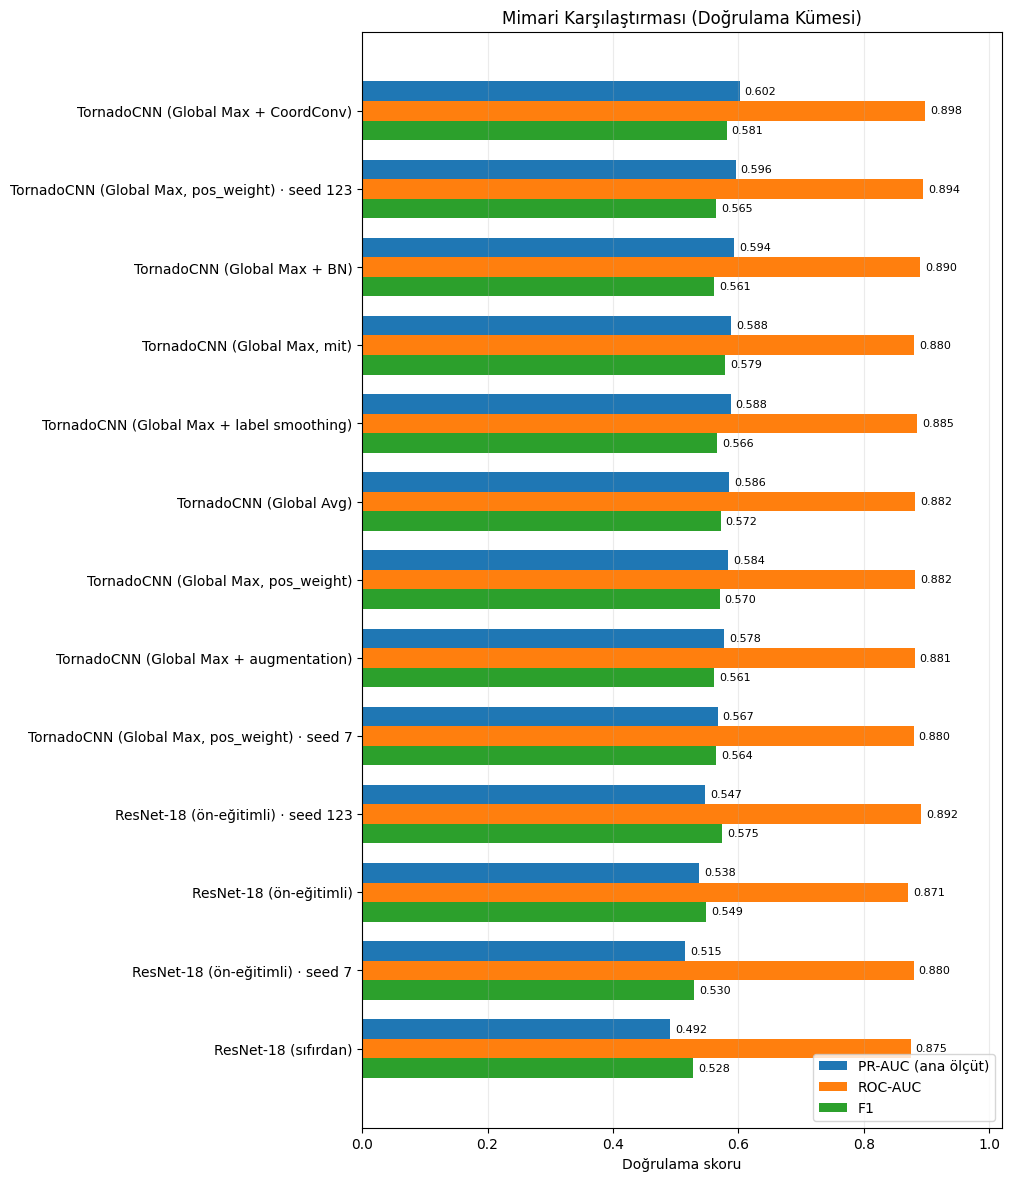

In [19]:
if not table.empty:
    plot_df = table.sort_values("PR-AUC", ascending=True)
    y_pos = np.arange(len(plot_df))
    h = 0.25

    fig, ax = plt.subplots(figsize=(10, max(3.6, 0.9 * len(plot_df))), layout="constrained")
    ax.barh(y_pos + h, plot_df["PR-AUC"], height=h, label="PR-AUC (ana ölçüt)")
    ax.barh(y_pos, plot_df["ROC-AUC"], height=h, label="ROC-AUC")
    ax.barh(y_pos - h, plot_df["F1"], height=h, label="F1")

    for i, (_, r) in enumerate(plot_df.iterrows()):
        ax.text(r["PR-AUC"] + 0.008, y_pos[i] + h, f"{r['PR-AUC']:.3f}", va="center", fontsize=8)
        ax.text(r["ROC-AUC"] + 0.008, y_pos[i], f"{r['ROC-AUC']:.3f}", va="center", fontsize=8)
        ax.text(r["F1"] + 0.008, y_pos[i] - h, f"{r['F1']:.3f}", va="center", fontsize=8)

    ax.set_yticks(y_pos, plot_df["Model"])
    ax.set_xlim(0, 1.02)
    ax.set_xlabel("Doğrulama skoru")
    ax.set_title("Mimari Karşılaştırması (Doğrulama Kümesi)")
    ax.grid(axis="x", alpha=0.25)
    ax.legend(loc="lower right")
    fig.savefig(RESULTS_DIR / f"metrics_comparison{SUFFIX}.png", dpi=150)
    plt.show()

## 4. Test kümesi değerlendirmesi (Faz 3)

Buraya kadarki bütün sayılar **doğrulama** kümesindendi; en iyi tur ve eşik de orada seçildi. Bu bölüm modelleri hiç görmedikleri **test** kümesinde (veri setinin hazır test kısmı) değerlendirir.

* **Eşik dondurulur (H5):** Her model kendi doğrulama eşiğini (`results.json`) kullanır. Eşik, doğrulamada F1'i, dolayısıyla CSI'yı en büyük yapan değerdir (M2).
* **Ölçütler (M1):** PR-AUC (ana ölçüt), ROC-AUC, POD (yakalama), SR (1 − yanlış alarm oranı), CSI, F1 ve Bias (tahmin edilen / gerçek hortum sayısı).
* **Güven aralıkları (M3):** %95 bootstrap, **fırtına bazlı**: fırtınalar (episode) yerine koyarak seçilir. Aynı fırtınanın kareleri birbirine çok benzediği için kare bazlı bootstrap aralıkları yapay olarak daraltırdı. Bütün modeller aynı örneklemlerle değerlendirilir; böylece temel modele fark (Δ) da eşleştirilmiş olarak hesaplanır.
* **Ensemble (O3):** 3 seed ile eğitilen modellerin skor ortalaması; eşiği yine doğrulamada seçilir.

İlk hücre doğrulama ve test kümelerini belleğe alır (yaklaşık 1,7 GB) ve her modelin skorlarını hesaplar ya da `preds.parquet`'ten okur.

In [20]:
import time

from src.app import models as M
from src.helper import evaluate as ev
from src.helper import train

device = train.get_device()
cfg_data = paths.load_config("data.json")
try:
    data_root, _ = paths.prepare_colab_dirs()
except FileNotFoundError:
    data_root = paths.data_dir()
splits = train.load_splits(data_root)
years = cfg_data["years"]
local_dir = Path("/content/data_local") if IN_COLAB else None
data, variables = train.load_data(paths.processed_dir(), splits, years, which=("val", "test"), local_dir=local_dir)
val_meta, test_meta = data["val"]["meta"], data["test"]["meta"]
y_val, y_test = data["val"]["y"], data["test"]["y"]
print(f"cihaz: {device} | doğrulama: {len(y_val):,} ({int(y_val.sum())} hortum) | "
      f"test: {len(y_test):,} ({int(y_test.sum())} hortum, oran {y_test.mean():.3f})")

INFOS = {}
for folder, _, mdir in found:
    INFOS[folder] = next(m for m in M.discover(mdir.parent) if m.key == folder)


def model_scores(info):
    """Doğrulama ve test skorları: preds.parquet güncelse oradan, değilse model çalıştırılır ve kaydedilir."""
    need = pd.concat([val_meta["filename"], test_meta["filename"]])
    if info.has_preds and not info.preds_stale:
        s = M.load_preds(info)
        if need.isin(s.index).all():
            return s.reindex(val_meta["filename"]).to_numpy(), s.reindex(test_meta["filename"]).to_numpy()
    if list(info.results.get("variables") or variables) != list(variables):
        raise ValueError(f"{info.key}: farklı kanallarla eğitilmiş")
    net = M.load_model(info, device)
    out = {}
    for split in ("val", "test"):
        d = data[split]
        out[split] = M.predict_images(net, d["X"], variables, batch=256, device=device,
                                      r0_km=train.range_km(d["meta"]))
    del net
    new = pd.DataFrame({"filename": need.to_numpy(), "prob": np.concatenate([out["val"], out["test"]])})
    try:                                                # paylaşılan Drive salt-okunur olabilir
        if info.has_preds:
            old = pd.read_parquet(info.preds_path)
            new = pd.concat([old[~old["filename"].isin(new["filename"])], new], ignore_index=True)
        new.to_parquet(info.preds_path, index=False)
    except OSError as e:
        print(f"  (uyarı) {info.preds_path} yazılamadı: {e}")
    return out["val"], out["test"]


SCORES, THR, LABELS = {}, {}, {}
for folder, label, _ in found:
    t0 = time.time()
    SCORES[folder] = dict(zip(("val", "test"), model_scores(INFOS[folder])))
    THR[folder] = INFOS[folder].threshold                     # doğrulamada seçilen eşik (H5)
    LABELS[folder] = label
    print(f"{folder:30s} test PR-AUC {ev.summarize(y_test, SCORES[folder]['test'], THR[folder])['PR-AUC']:.4f} "
          f"| {time.time() - t0:.0f} sn")

# O3: seed ensemble'ları (birden fazla seed klasörü olan deneyler)
groups = {}
for folder in SCORES:
    groups.setdefault(seed_group(folder)[0], []).append(folder)
ENSEMBLES = {}
for base, members in groups.items():
    if len(members) >= 2:
        key = f"{base}_ens"
        SCORES[key] = {s: ev.ensemble([SCORES[m][s] for m in members]) for s in ("val", "test")}
        THR[key] = train.choose_threshold(y_val, SCORES[key]["val"])
        LABELS[key] = f"{EXPERIMENTS.get(base, base)} · ensemble ({len(members)} seed)"
        ENSEMBLES[key] = members
        print(f"{key:30s} ensemble: {members} | eşik {THR[key]:.3f}")

cihaz: cuda | doğrulama: 8,040 (690 hortum) | test: 11,078 (797 hortum, oran 0.072)
03_baseline                    test PR-AUC 0.4842 | 0 sn
03_mit                         test PR-AUC 0.4991 | 0 sn
05_cnn_avg                     test PR-AUC 0.4853 | 0 sn
05_resnet18_pretrained         test PR-AUC 0.4281 | 0 sn
05_resnet18_scratch            test PR-AUC 0.3851 | 0 sn
05_cnn_bn                      test PR-AUC 0.5406 | 0 sn
05_cnn_coord                   test PR-AUC 0.5340 | 0 sn
05_cnn_aug                     test PR-AUC 0.5198 | 0 sn
05_cnn_ls                      test PR-AUC 0.4945 | 0 sn
03_baseline_s123               test PR-AUC 0.5159 | 0 sn
03_baseline_s7                 test PR-AUC 0.5168 | 0 sn
05_resnet18_pretrained_s123    test PR-AUC 0.4754 | 0 sn
05_resnet18_pretrained_s7      test PR-AUC 0.4138 | 0 sn
03_baseline_ens                ensemble: ['03_baseline', '03_baseline_s123', '03_baseline_s7'] | eşik 0.749
05_resnet18_pretrained_ens     ensemble: ['05_resnet18_pretrained',

### 4.1 Test sonuçları ve %95 güven aralıkları

Köşeli parantez içindeki değerler fırtına bazlı bootstrap %95 güven aralığıdır.

**Δ PR-AUC** temel modelin **3 seed ortalamasına** göre hesaplanır, tek bir seed'e göre değil. Tek seed referans alınırsa o seed'in şansı bütün satırlara yansır; örneğin seed 42 testte üç seed'in en zayıfı çıktı. İki ayrı belirsizlik vardır:

* **Test örneklemi:** Güven aralığı bunu ölçer. Aynı bootstrap örneklemlerinde modelin PR-AUC'sinden temel seed'lerin ortalaması çıkarılır.
* **Eğitim (seed):** Güven aralığı bunu görmez. Tek seed'le eğitilen bir ablasyon şanslı ya da şanssız bir seed'e denk gelmiş olabilir. Ölçüsü temel modelin seed std'si σ'dır (M3).

**Yorum** sütunu ikisini birlikte okur:

| Yorum | Koşul |
|---|---|
| fark | Güven aralığı sıfırı içermiyor ve \|Δ\| > 2σ |
| eğilim | \|Δ\| > σ |
| gürültü | Diğer durumlar |

Temel modelin kendi seed'leri ve ensemble'ı için yorum yapılmaz.

Ana karşılaştırmanın 3 seed'li modelleri için ayrıca seed'ler arası ortalama ± std verilir.

In [21]:
N_BOOT = 1000                     # süre: model başına birkaç saniye
BASE = "03_baseline"
boot_idx = ev.bootstrap_indices(test_meta["episode_id"], n_boot=N_BOOT, seed=0)
BOOTS = {}
for k in SCORES:
    BOOTS[k] = ev.bootstrap(y_test, SCORES[k]["test"], THR[k], boot_idx)

# Δ referansı: temel modelin seed'lerinin ortalaması (tek seed'in şansı bütün satırlara yansımasın)
REF = ENSEMBLES.get(f"{BASE}_ens", [BASE] if BASE in SCORES else [])
if REF:
    ref_vals = [ev.summarize(y_test, SCORES[m]["test"], THR[m])["PR-AUC"] for m in REF]
    REF_PR = float(np.mean(ref_vals))
    SEED_SD = float(np.std(ref_vals, ddof=1)) if len(REF) > 1 else float("nan")
    REF_BOOT = np.mean([BOOTS[m]["PR-AUC"].to_numpy() for m in REF], axis=0)

rows = []
for k in SCORES:
    s = ev.summarize(y_test, SCORES[k]["test"], THR[k])
    v = ev.summarize(y_val, SCORES[k]["val"], THR[k])
    row = {
        "Klasör": k, "Model": LABELS[k], "Eşik (val)": round(THR[k], 3),
        "val PR-AUC": round(v["PR-AUC"], 4),
        "PR-AUC": s["PR-AUC"],
        "PR-AUC [%95 GA]": ev.fmt_ci(s["PR-AUC"], BOOTS[k]["PR-AUC"]),
        "ROC-AUC [%95 GA]": ev.fmt_ci(s["ROC-AUC"], BOOTS[k]["ROC-AUC"]),
        "POD": round(s["POD"], 3), "SR": round(s["SR"], 3),
        "CSI [%95 GA]": ev.fmt_ci(s["CSI"], BOOTS[k]["CSI"]),
        "F1": round(s["F1"], 3), "Bias": round(s["Bias"], 2),
    }
    if REF:
        d = s["PR-AUC"] - REF_PR
        lo, hi = ev.ci(BOOTS[k]["PR-AUC"].to_numpy() - REF_BOOT)
        row["Δ PR-AUC [%95 GA]"] = f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]"
        row["Δ / σ"] = round(d / SEED_SD, 1) if SEED_SD == SEED_SD else None
        if k in REF or k == f"{BASE}_ens":
            row["Yorum"] = "temel model"
        elif not (lo <= 0 <= hi) and abs(d) > 2 * SEED_SD:
            row["Yorum"] = "fark"
        elif abs(d) > SEED_SD:
            row["Yorum"] = "eğilim"
        else:
            row["Yorum"] = "gürültü"
    rows.append(row)
test_table = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).drop(columns="PR-AUC").reset_index(drop=True)
test_table.to_csv(RESULTS_DIR / "test_results.csv", index=False)
print(f"Test: {len(y_test):,} kare, {test_meta['episode_id'].nunique():,} fırtına | rastgele modelin PR-AUC'si {y_test.mean():.3f}")
if REF:
    print(f"Δ referansı: {BASE} seed ortalaması {REF_PR:.4f} ({len(REF)} seed) | seed std σ = {SEED_SD:.4f}")
display(test_table)

# Seed'ler arası ortalama ± std (test)
seed_rows = []
for key, members in ENSEMBLES.items():
    vals = pd.DataFrame([ev.summarize(y_test, SCORES[m]["test"], THR[m]) for m in members])
    seed_rows.append({"Deney": key.removesuffix("_ens"), "seed": len(members),
                      **{c: f"{vals[c].mean():.4f} ± {vals[c].std():.4f}" for c in ["PR-AUC", "ROC-AUC", "CSI", "F1"]},
                      "ensemble PR-AUC": round(ev.summarize(y_test, SCORES[key]["test"], THR[key])["PR-AUC"], 4)})
if seed_rows:
    test_seed_table = pd.DataFrame(seed_rows).set_index("Deney")
    test_seed_table.to_csv(RESULTS_DIR / "test_seed_summary.csv")
    display(test_seed_table)

Test: 11,078 kare, 603 fırtına | rastgele modelin PR-AUC'si 0.072
* : Δ aralığı sıfırı içermiyor


,Klasör,Model,Eşik (val),val PR-AUC,PR-AUC [%95 GA],ROC-AUC [%95 GA],POD,SR,CSI [%95 GA],F1,Bias,Δ PR-AUC [%95 GA]
0,05_cnn_bn,TornadoCNN (Global Max + BN),0.822,0.5939,"0.541 [0.432, 0.639]","0.885 [0.860, 0.909]",0.551,0.455,"0.332 [0.261, 0.406]",0.498,1.21,"+0.056 [+0.028, +0.084] *"
1,05_cnn_coord,TornadoCNN (Global Max + CoordConv),0.908,0.6022,"0.534 [0.423, 0.635]","0.881 [0.855, 0.906]",0.558,0.504,"0.360 [0.292, 0.433]",0.530,1.11,"+0.050 [+0.009, +0.089] *"
2,05_cnn_aug,TornadoCNN (Global Max + augmentation),0.887,0.5776,"0.520 [0.415, 0.621]","0.873 [0.844, 0.900]",0.491,0.481,"0.321 [0.252, 0.390]",0.486,1.02,"+0.036 [+0.004, +0.065] *"
3,03_baseline_ens,"TornadoCNN (Global Max, pos_weight) · ensemble...",0.749,0.6022,"0.519 [0.415, 0.617]","0.872 [0.844, 0.899]",0.561,0.427,"0.320 [0.250, 0.395]",0.485,1.31,"+0.034 [+0.017, +0.050] *"
4,03_baseline_s7,"TornadoCNN (Global Max, pos_weight) · seed 7",0.746,0.5671,"0.517 [0.412, 0.618]","0.868 [0.838, 0.894]",0.583,0.394,"0.307 [0.239, 0.379]",0.470,1.48,"+0.033 [-0.002, +0.065]"
5,03_baseline_s123,"TornadoCNN (Global Max, pos_weight) · seed 123",0.844,0.5955,"0.516 [0.410, 0.614]","0.870 [0.841, 0.897]",0.518,0.456,"0.320 [0.252, 0.392]",0.485,1.14,"+0.032 [+0.001, +0.059] *"
6,03_mit,"TornadoCNN (Global Max, mit)",0.348,0.5883,"0.499 [0.389, 0.599]","0.869 [0.841, 0.895]",0.531,0.449,"0.321 [0.254, 0.394]",0.486,1.18,"+0.015 [-0.017, +0.044]"
7,05_cnn_ls,TornadoCNN (Global Max + label smoothing),0.790,0.5879,"0.494 [0.392, 0.591]","0.869 [0.843, 0.895]",0.478,0.500,"0.323 [0.257, 0.388]",0.489,0.96,"+0.010 [-0.030, +0.051]"
8,05_cnn_avg,TornadoCNN (Global Avg),0.795,0.5858,"0.485 [0.376, 0.589]","0.877 [0.852, 0.900]",0.497,0.449,"0.309 [0.242, 0.375]",0.472,1.11,"+0.001 [-0.029, +0.028]"
9,03_baseline,"TornadoCNN (Global Max, pos_weight)",0.731,0.5843,"0.484 [0.385, 0.582]","0.856 [0.824, 0.886]",0.516,0.406,"0.294 [0.228, 0.362]",0.454,1.27,NaN


,seed,PR-AUC,ROC-AUC,CSI,F1,ensemble PR-AUC
Deney,,,,,,
03_baseline,3,0.5056 ± 0.0186,0.8644 ± 0.0077,0.3071 ± 0.0132,0.4698 ± 0.0154,0.5185
05_resnet18_pretrained,3,0.4391 ± 0.0323,0.8661 ± 0.0139,0.3057 ± 0.0111,0.4682 ± 0.0131,0.4762


### 4.2 NC / RC / WC görünümleri (karar S2)

Eğitim ikili kaldı; test kümesi kategoriye göre süzülerek üç soru ayrı ayrı sorulur:

| Görünüm | Pozitif | Negatif | Soru |
|---|---|---|---|
| NC | TOR | WRN + NUL | Genel başarım |
| RC | TOR | NUL | Hortumu sıradan fırtınadan ayırabiliyor mu? (kolay) |
| WC | TOR | WRN | Hortumu uyarı verilmiş ama hortum çıkmamış fırtınadan ayırabiliyor mu? (zor) |

Görünümlerin hortum oranı farklı olduğundan PR-AUC'ler görünümler arasında doğrudan kıyaslanmaz; aynı görünümde modeller kıyaslanır. ROC-AUC orandan bağımsızdır.

In [22]:
view_rows = []
for k in SCORES:
    t = ev.view_table(test_meta, SCORES[k]["test"], THR[k])
    for v, r in t.iterrows():
        view_rows.append({"Model": LABELS[k], "görünüm": v, "PR-AUC": r["PR-AUC"], "ROC-AUC": r["ROC-AUC"],
                          "CSI": r["CSI"], "hortum oranı": r["hortum oranı"]})
views = pd.DataFrame(view_rows)
view_table = views.pivot_table(index="Model", columns="görünüm", values=["PR-AUC", "ROC-AUC", "CSI"], sort=False)
view_table = view_table.sort_values(("PR-AUC", "NC"), ascending=False).round(3)
view_table.to_csv(RESULTS_DIR / "test_views.csv")
rates = views.drop_duplicates("görünüm").set_index("görünüm")["hortum oranı"]
print("Hortum oranı (rastgele modelin PR-AUC'si):", ", ".join(f"{v} {r:.3f}" for v, r in rates.items()))
display(view_table)

Hortum oranı (rastgele modelin PR-AUC'si): NC 0.072, RC 0.117, WC 0.157


PR-AUC                \
görünüm                                                NC     RC     WC   
Model                                                                     
TornadoCNN (Global Max + BN)                        0.541  0.782  0.576   
TornadoCNN (Global Max + CoordConv)                 0.534  0.780  0.568   
TornadoCNN (Global Max + augmentation)              0.520  0.763  0.556   
TornadoCNN (Global Max, pos_weight) · ensemble ...  0.519  0.768  0.552   
TornadoCNN (Global Max, pos_weight) · seed 7        0.517  0.751  0.556   
TornadoCNN (Global Max, pos_weight) · seed 123      0.516  0.771  0.548   
TornadoCNN (Global Max, mit)                        0.499  0.770  0.532   
TornadoCNN (Global Max + label smoothing)           0.494  0.755  0.531   
TornadoCNN (Global Avg)                             0.485  0.754  0.523   
TornadoCNN (Global Max, pos_weight)                 0.484  0.727  0.524   
ResNet-18 (ön-eğitimli) · ensemble (3 seed)         0.476  0.781  0.512   
ResNet-18 (ön-eğitimli) · seed 123                  0.475  0.773  0.509   
ResNet-18 (ön-eğitimli)                             0.428  0.718  0.470   
ResNet-18 (ön-eğitimli) · seed 7                    0.414  0.719  0.462   
ResNet-18 (sıfırdan)                                0.385  0.683  0.428   

                                                   ROC-AUC                \
görünüm                                                 NC     RC     WC   
Model                                                                      
TornadoCNN (Global Max + BN)                         0.885  0.933  0.817   
TornadoCNN (Global Max + CoordConv)                  0.881  0.933  0.807   
TornadoCNN (Global Max + augmentation)               0.873  0.925  0.800   
TornadoCNN (Global Max, pos_weight) · ensemble ...   0.872  0.928  0.794   
TornadoCNN (Global Max, pos_weight) · seed 7         0.868  0.919  0.796   
TornadoCNN (Global Max, pos_weight) · seed 123       0.870  0.927  0.791   
TornadoCNN (Global Max, mit)                         0.869  0.929  0.786   
TornadoCNN (Global Max + label smoothing)            0.869  0.927  0.788   
TornadoCNN (Global Avg)                              0.877  0.933  0.798   
TornadoCNN (Global Max, pos_weight)                  0.856  0.913  0.776   
ResNet-18 (ön-eğitimli) · ensemble (3 seed)          0.886  0.939  0.812   
ResNet-18 (ön-eğitimli) · seed 123                   0.880  0.935  0.803   
ResNet-18 (ön-eğitimli)                              0.852  0.909  0.773   
ResNet-18 (ön-eğitimli) · seed 7                     0.867  0.914  0.800   
ResNet-18 (sıfırdan)                                 0.839  0.907  0.744   

                                                      CSI                
görünüm                                                NC     RC     WC  
Model                                                                    
TornadoCNN (Global Max + BN)                        0.332  0.498  0.354  
TornadoCNN (Global Max + CoordConv)                 0.360  0.514  0.381  
TornadoCNN (Global Max + augmentation)              0.321  0.451  0.340  
TornadoCNN (Global Max, pos_weight) · ensemble ...  0.320  0.502  0.343  
TornadoCNN (Global Max, pos_weight) · seed 7        0.307  0.504  0.335  
TornadoCNN (Global Max, pos_weight) · seed 123      0.320  0.479  0.337  
TornadoCNN (Global Max, mit)                        0.321  0.490  0.339  
TornadoCNN (Global Max + label smoothing)           0.323  0.448  0.339  
TornadoCNN (Global Avg)                             0.309  0.450  0.330  
TornadoCNN (Global Max, pos_weight)                 0.294  0.453  0.319  
ResNet-18 (ön-eğitimli) · ensemble (3 seed)         0.332  0.532  0.357  
ResNet-18 (ön-eğitimli) · seed 123                  0.315  0.483  0.335  
ResNet-18 (ön-eğitimli)                             0.293  0.448  0.312  
ResNet-18 (ön-eğitimli) · seed 7                    0.309  0.457  0.333  
ResNet-18 (sıfırdan)                                0.255  0.432  0.282

### 4.3 Grafikler (karar M4)

Grafiklerde ana karşılaştırma (ensemble'lar) ve öne çıkan ablasyonlar gösterilir; `PLOT` listesinden değiştirilebilir.

* **Performans diyagramı** (Roebber, 2009): PR eğrisinin meteorolojideki karşılığı. x ekseni SR (isabet), y ekseni POD (yakalama); gri dolgu CSI, kesikli doğrular frekans yanlılığı (Bias). Noktalar doğrulamada seçilen eşikteki karardır. Sağ üst köşeye yakın olan iyidir.
* **ROC eğrisi:** literatürle kıyas için.

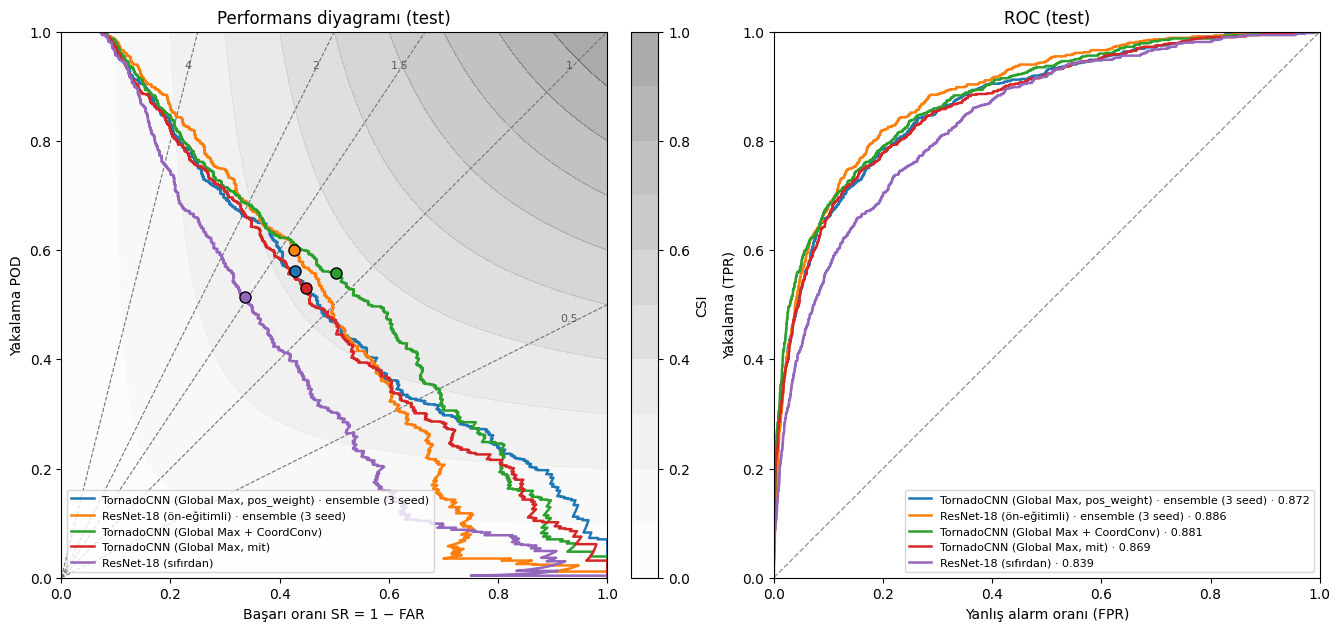

In [23]:
PLOT = [k for k in ["03_baseline_ens", "05_resnet18_pretrained_ens", "05_cnn_coord", "03_mit", "05_resnet18_scratch"]
        if k in SCORES] or list(SCORES)[:5]

from sklearn.metrics import roc_auc_score, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), layout="constrained")
ev.performance_diagram(axes[0], [(LABELS[k], y_test, SCORES[k]["test"]) for k in PLOT],
                       [(LABELS[k], y_test, SCORES[k]["test"], THR[k]) for k in PLOT])
axes[0].set_title("Performans diyagramı (test)")
axes[1].plot([0, 1], [0, 1], color="0.6", ls="--", lw=1)
for k in PLOT:
    fpr, tpr, _ = roc_curve(y_test, SCORES[k]["test"])
    axes[1].plot(fpr, tpr, lw=1.8, label=f"{LABELS[k]} · {roc_auc_score(y_test, SCORES[k]['test']):.3f}")
axes[1].set(xlim=(0, 1), ylim=(0, 1), xlabel="Yanlış alarm oranı (FPR)", ylabel="Yakalama (TPR)", title="ROC (test)",
            aspect="equal")
axes[1].legend(fontsize=8, loc="lower right")
fig.savefig(RESULTS_DIR / "test_performance_roc.png", dpi=150)
plt.show()

**Güvenilirlik diyagramı:** Skor 0,8 olan karelerin gerçekten %80'i hortum mu? Köşegen tam kalibrasyondur. `pos_weight` hortum sınıfını yaklaşık 12 kat ağırlıklandırdığı için skorların köşegenin **altında** kalması, yani gerçek orandan yüksek çıkması beklenir. `mit` şeması (`pos_weight = 1`) köşegene daha yakın olmalıdır. Bu yüzden arayüzde gösterilen değer "olasılık" değil **skor**dur (X8).

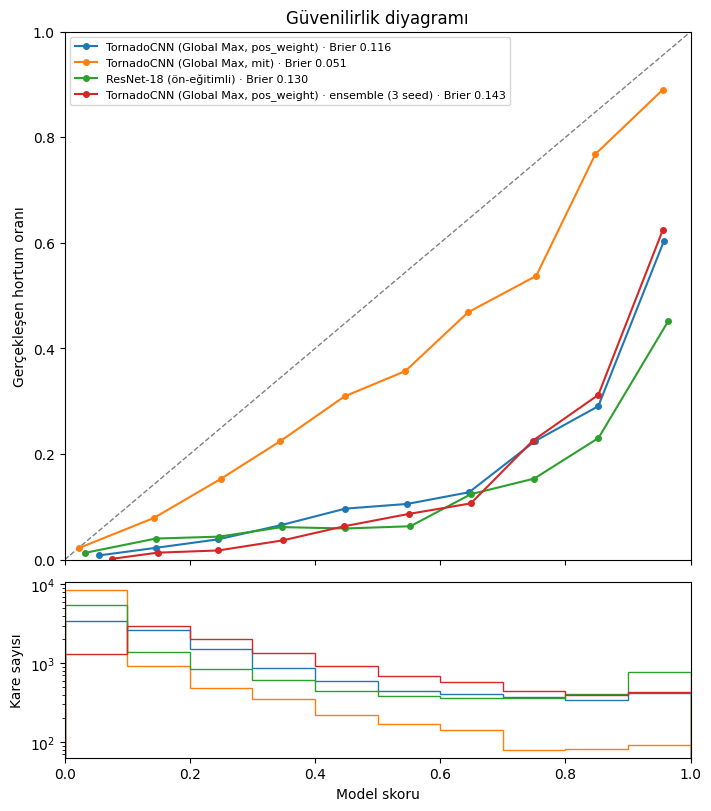

In [24]:
REL = [k for k in ["03_baseline", "03_mit", "05_resnet18_pretrained", "03_baseline_ens"] if k in SCORES]
fig, (ax, axh) = plt.subplots(2, 1, figsize=(7, 8), height_ratios=[3, 1], sharex=True, layout="constrained")
ev.reliability_diagram(ax, axh, [(LABELS[k], y_test, SCORES[k]["test"]) for k in REL])
fig.savefig(RESULTS_DIR / "test_reliability.png", dpi=150)
plt.show()

**EF'ye göre skor dağılımı:** Kutular medyan ve çeyrekleri gösterir; kırmızı çizgi eşiktir. Güçlü hortumların (EF2+) skorunun zayıflardan (EF0) yüksek olması, WRN'nin ise NUL ile TOR arasında kalması beklenir [V25 Şekil B3]. Tablolarda "eşiği geçen oran" TOR sınıflarında POD, WRN ve NUL'da yanlış alarm oranıdır.

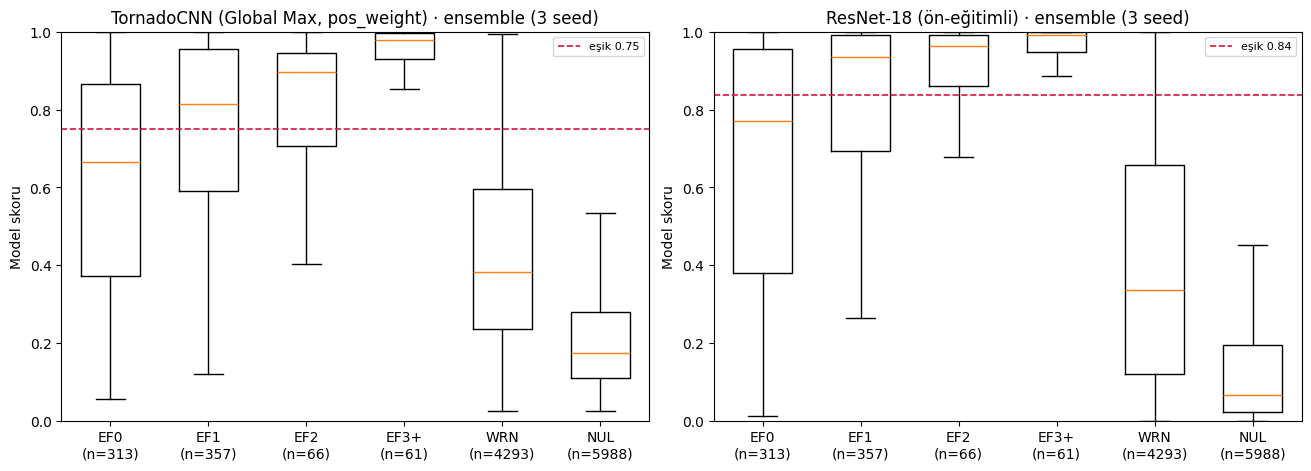

TornadoCNN (Global Max, pos_weight) · ensemble (3 seed)              \
                                                            n medyan skor   
sınıf                                                                       
EF0                                                  313            0.665   
EF1                                                  357            0.814   
EF2                                                   66            0.895   
EF3+                                                  61            0.979   
WRN                                                 4293            0.383   
NUL                                                 5988            0.176   

                       ResNet-18 (ön-eğitimli) · ensemble (3 seed)  \
      eşiği geçen oran                                           n   
sınıf                                                                
EF0              0.406                                         313   
EF1              0.608                                         357   
EF2              0.697                                          66   
EF3+             0.934                                          61   
WRN              0.118                                        4293   
NUL              0.016                                        5988   

                                    
      medyan skor eşiği geçen oran  
sınıf                               
EF0         0.771            0.435  
EF1         0.936            0.669  
EF2         0.962            0.758  
EF3+        0.993            0.885  
WRN         0.335            0.126  
NUL         0.068            0.017

In [25]:
EFM = [k for k in ["03_baseline_ens", "05_resnet18_pretrained_ens"] if k in SCORES] or PLOT[:2]
fig, axes = plt.subplots(1, len(EFM), figsize=(6.5 * len(EFM), 4.6), layout="constrained", squeeze=False)
for ax, k in zip(axes[0], EFM):
    ev.ef_plot(ax, test_meta, SCORES[k]["test"], THR[k], title=LABELS[k])
fig.savefig(RESULTS_DIR / "test_ef_scores.png", dpi=150)
plt.show()
ef_all = pd.concat({LABELS[k]: ev.ef_table(test_meta, SCORES[k]["test"], THR[k]) for k in EFM}, axis=1).round(3)
ef_all.to_csv(RESULTS_DIR / "test_ef_table.csv")
display(ef_all)

**Radara uzaklığa göre başarım:** CoordConv'un (K4) doğrudan sınavı. Radar ışını uzaklaştıkça genişler ve yükselir; mezosiklon daha kaba çözünürlükte görünür. Başarımın uzaklıkla düşmesi beklenir. CoordConv modelin uzaklığı bilmesini sağlıyor; bu düşüşü azaltıyorsa uzak aralıklarda temel modelden iyi olmalıdır.

Uzaklık, pencere merkezinin radara uzaklığıdır (`rng_min` + 30 km). Aralıklar arası kıyas için ROC-AUC esas alınır; PR-AUC aralığın hortum oranına bağlıdır.

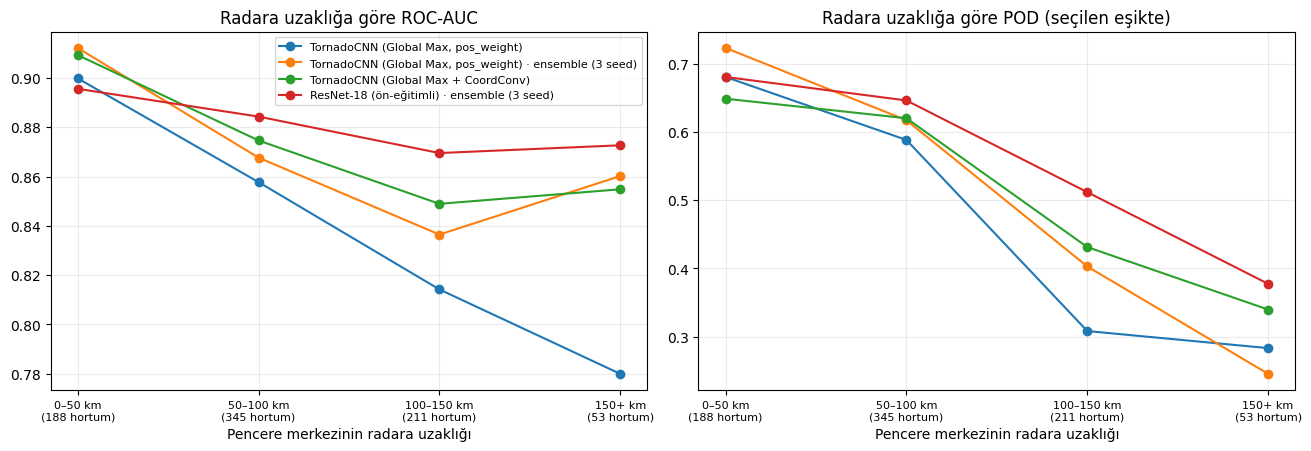

TornadoCNN (Global Max, pos_weight)                              \
                                             n hortum hortum oranı ROC-AUC   
uzaklık                                                                      
0–50 km                                   1811    188        0.104   0.900   
50–100 km                                 3825    345        0.090   0.858   
100–150 km                                3323    211        0.063   0.814   
150+ km                                   2119     53        0.025   0.780   

                                 \
           PR-AUC    POD    CSI   
uzaklık                           
0–50 km     0.653  0.681  0.376   
50–100 km   0.546  0.588  0.338   
100–150 km  0.289  0.308  0.179   
150+ km     0.250  0.283  0.160   

           TornadoCNN (Global Max, pos_weight) · ensemble (3 seed)         \
                                                                 n hortum   
uzaklık                                                                     
0–50 km                                                  1811         188   
50–100 km                                                3825         345   
100–150 km                                               3323         211   
150+ km                                                  2119          53   

                         ... TornadoCNN (Global Max + CoordConv)         \
           hortum oranı  ...                              PR-AUC    POD   
uzaklık                  ...                                              
0–50 km           0.104  ...                               0.633  0.649   
50–100 km         0.090  ...                               0.598  0.620   
100–150 km        0.063  ...                               0.404  0.431   
150+ km           0.025  ...                               0.250  0.340   

                  ResNet-18 (ön-eğitimli) · ensemble (3 seed)         \
              CSI                                           n hortum   
uzaklık                                                                
0–50 km     0.434                                        1811    188   
50–100 km   0.410                                        3825    345   
100–150 km  0.261                                        3323    211   
150+ km     0.217                                        2119     53   

                                                      
           hortum oranı ROC-AUC PR-AUC    POD    CSI  
uzaklık                                               
0–50 km           0.104   0.896  0.578  0.681  0.365  
50–100 km         0.090   0.884  0.511  0.646  0.374  
100–150 km        0.063   0.870  0.419  0.512  0.290  
150+ km           0.025   0.873  0.161  0.377  0.161  

[4 rows x 28 columns]

In [26]:
RNG = [k for k in ["03_baseline", "03_baseline_ens", "05_cnn_coord", "05_resnet18_pretrained_ens"] if k in SCORES]
rng_tables = {LABELS[k]: ev.range_table(test_meta, SCORES[k]["test"], THR[k]) for k in RNG}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
ev.range_plot(axes, rng_tables)
fig.savefig(RESULTS_DIR / "test_range.png", dpi=150)
plt.show()
rng_all = pd.concat(rng_tables, axis=1).round(3)
rng_all.to_csv(RESULTS_DIR / "test_range_table.csv")
display(rng_all)